<a href="https://colab.research.google.com/github/wenh08/Python_projects-/blob/main/Hospital_Project_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# New York State Hospital Inpatient Discharges | 2024

**Python data analysis project**  
**Source:** New York State SPARCS de-identified inpatient discharge records (2024)  
**Working dataset:** 400,000 discharge records, with 15 columns selected from the original 33  
**Tools:** Google Colab, Python, Pandas, Seaborn, and Matplotlib

### Why I chose this project

Working in healthcare made me curious about what hospital data could tell us beyond the day-to-day work. I wanted to look at which diagnoses appear most often, what kinds of hospitalizations cost the most, how long patients stay, and whether those patterns differ across demographic groups. Once I noticed a difference in septicemia outcomes between Black and White patients, I decided to take a closer look at age and illness severity too.

### Questions I explored

1. Which diagnosis categories appear most often in the discharge records?
2. Which diagnosis-related groups (DRGs) have the highest **average estimated hospital costs**?
3. Which DRGs have the longest **average hospital stays**?
4. How do hospital costs compare across illness severity levels **within the same DRG**?
5. How do the most common diagnoses, average costs, and hospital stays differ by **age, gender, and race**?
6. **Additional finding:** Do racial differences in septicemia costs and stays persist when I compare hospitalizations by recorded severity and age group?

**A note about the data:** This is a 400,000-record working subset of a larger dataset; I have not established that the subset is random or representative of all New York State hospitalizations. Each row represents a **hospital discharge**, not necessarily a different person. `Costs` refers to **estimated hospital costs**, not patients' bills or insurance payments. My findings describe patterns in this sample; they do not prove what caused those patterns.

## 1. Load my dataset

I start by loading the 400,000-row CSV I already saved in Google Drive. There is no need to overwrite the original file each time I run the notebook.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount("/content/drive")

# Load the saved working sample without overwriting the CSV.
df = pd.read_csv(
    "/content/drive/MyDrive/Hospital_2024_400K.csv",
    low_memory=False
)
df.shape


Mounted at /content/drive


(400000, 33)

## 2. Get familiar with the data

Before cleaning anything, I checked the first and last records, reviewed the data types, and looked for missing values. I wanted to understand what I was working with before making changes. These checks don't remove any records.

In [3]:
# Preview the first 10 records.
df.head(10)


,Health Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
0,New York City,New York,7002020.0,1453.0,MEMORIAL HOSPITAL FOR CANCER AND ALLIED DISEASES,50-69,125,M,White,Not Span/Hispanic,...,Extreme,Extreme,Medical,Blue Cross/Blue Shield,NaN,NaN,NaN,Y,449321.39,145177.97
1,Hudson Valley,Westchester,5957001.0,1139.0,WESTCHESTER MEDICAL CENTER,50-69,125,M,White,Not Span/Hispanic,...,Extreme,Major,Surgical,Medicare,Private Health Insurance,NaN,NaN,N,1118813.45,192747.71
2,Long Island,Suffolk,5157003.0,943.0,ST CATHERINE OF SIENA HOSPITAL,70 or Older,NaN,F,Other Race,Not Span/Hispanic,...,Moderate,Minor,Surgical,Medicare,Blue Cross/Blue Shield,Private Health Insurance,NaN,N,111718.78,21940.79
3,New York City,New York,7002054.0,1464.0,NEW YORK-PRESBYTERIAN HOSPITAL - COLUMBIA PRES...,70 or Older,100,F,Other Race,Spanish/Hispanic,...,Moderate,Moderate,Medical,Medicaid,NaN,NaN,NaN,Y,109000.53,21478.63
4,Long Island,Suffolk,5154000.0,924.0,SOUTH SHORE UNIVERSITY HOSPITAL,50-69,117,M,Other Race,Spanish/Hispanic,...,Minor,Minor,Surgical,Miscellaneous/Other,NaN,NaN,NaN,N,63682.26,24109.54
5,New York City,Bronx,7000006.0,3058.0,MONTEFIORE MED CENTER - JACK D WEILER HOSP OF ...,70 or Older,104,F,Other Race,Spanish/Hispanic,...,Minor,Moderate,Medical,Medicare,Medicaid,NaN,NaN,Y,41245.13,7166.43
6,New York City,Bronx,7000001.0,1178.0,BRONXCARE HOSPITAL CENTER,50-69,NaN,M,Black/African American,Not Span/Hispanic,...,Extreme,Extreme,Medical,Medicaid,Medicaid,NaN,NaN,N,41960.70,31440.30
7,New York City,New York,7002024.0,1456.0,MOUNT SINAI HOSPITAL,0-17,112,M,White,Not Span/Hispanic,...,Minor,Minor,Medical,Private Health Insurance,NaN,NaN,3000,N,23243.00,1902.74
8,New York City,New York,7002020.0,1453.0,MEMORIAL HOSPITAL FOR CANCER AND ALLIED DISEASES,50-69,104,F,Other Race,Not Span/Hispanic,...,Minor,Minor,Surgical,Private Health Insurance,NaN,NaN,NaN,N,104189.39,41552.78
9,Central NY,Onondaga,3301003.0,630.0,ST. JOSEPH'S HOSPITAL HEALTH CENTER,50-69,136,M,White,Not Span/Hispanic,...,Major,Extreme,Surgical,Federal/State/Local/VA,NaN,NaN,NaN,N,110229.25,75709.84


In [4]:
# Preview the last 10 records.
df.tail(10)


,Health Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
399990,Hudson Valley,Westchester,5957001.0,1139.0,WESTCHESTER MEDICAL CENTER,18-29,105,F,Other Race,Unknown,...,Major,Minor,Medical,Medicaid,Medicaid,NaN,NaN,Y,336424.38,54822.42
399991,Capital/Adirondacks,Albany,101004.0,5.0,ST. PETER'S HOSPITAL,50-69,121,M,White,Not Span/Hispanic,...,Major,Major,Medical,Private Health Insurance,NaN,NaN,NaN,Y,58331.08,23604.23
399992,Long Island,Nassau,2950002.0,528.0,NASSAU UNIVERSITY MEDICAL CENTER,30-49,115,F,Other Race,Spanish/Hispanic,...,Moderate,Minor,Medical,Medicaid,Self-Pay,NaN,NaN,N,17911.37,6442.74
399993,New York City,New York,7002053.0,1463.0,NYU LANGONE HOSPITALS,70 or Older,112,M,White,Not Span/Hispanic,...,Major,Moderate,Medical,Medicare,Medicaid,NaN,NaN,Y,92606.23,33722.32
399994,New York City,New York,7002032.0,1469.0,MOUNT SINAI MORNINGSIDE,70 or Older,100,F,Black/African American,Not Span/Hispanic,...,Moderate,Major,Medical,Medicare,NaN,NaN,NaN,Y,118016.23,23503.22
399995,New York City,Richmond,7004003.0,1740.0,STATEN ISLAND UNIVERSITY HOSP-NORTH,50-69,103,M,Other Race,Spanish/Hispanic,...,Extreme,Extreme,Medical,Medicare,NaN,NaN,NaN,Y,144956.89,43921.94
399996,Hudson Valley,Westchester,5907002.0,1098.0,ST. JOSEPH'S MEDICAL CENTER,50-69,107,M,Black/African American,Not Span/Hispanic,...,Minor,Minor,Medical,Medicare,Medicare,Medicaid,NaN,Y,82719.32,36958.87
399997,Central NY,Onondaga,3301008.0,636.0,CROUSE HOSPITAL,50-69,132,F,Black/African American,Not Span/Hispanic,...,Moderate,Moderate,Medical,Medicaid,NaN,NaN,NaN,Y,25992.65,10290.28
399998,Capital/Adirondacks,Albany,101000.0,1.0,ALBANY MEDICAL CENTER HOSPITAL,0-17,128,M,White,Not Span/Hispanic,...,Minor,Minor,Medical,"Managed Care, Unspecified",NaN,NaN,NaN,Y,18123.85,4483.43
399999,New York City,New York,7002001.0,1438.0,BELLEVUE HOSPITAL CENTER,30-49,100,M,Black/African American,Unknown,...,Moderate,Moderate,Medical,Medicaid,NaN,NaN,NaN,N,81604.10,38090.67


In [5]:
# Identify each column's data type before cleaning.
df.dtypes


,0
Health Service Area,object
Hospital County,object
Operating Certificate Number,float64
Permanent Facility Id,float64
Facility Name,object
Age Group,object
Zip Code,object
Gender,object
Race,object
Ethnicity,object


In [6]:
# Report only columns with missing values and their percentages.
missing_report = df.isna().sum().sort_values(ascending=False)
missing_report = missing_report[missing_report > 0].to_frame(name="Missing Values")
missing_report["missing %"] = (
    missing_report["Missing Values"] / len(df) * 100
).round(2)
missing_report


,Missing Values,missing %
Birth Weight,369565,92.39
Payment Typology 3,358336,89.58
Payment Typology 2,224148,56.04
CCSR Procedure Description,120363,30.09
CCSR Procedure Code,120363,30.09
Zip Code,19961,4.99
Health Service Area,1348,0.34
Permanent Facility Id,1348,0.34
Hospital County,1348,0.34
Operating Certificate Number,1348,0.34


## 3. Clean the length-of-stay column

`Length of Stay` came in as text because some records contain `120+`. I converted it to a number so I could calculate averages and make graphs.

**Important detail:** `120+` means **at least 120 days**. Converting that label to `120` lets me analyze the column, but it also means some very long stays may be understated. The original field doesn't give the exact number of days beyond 120.

In [7]:
# Inspect the original values before converting the column.
df["Length of Stay"].unique()


array(['24', '29', '3', '6', '1', '2', '5', '10', '36', '8', '4', '7',
       '37', '13', '9', '16', '77', '31', '28', '12', '14', '120+', '15',
       '97', '23', '17', '11', '22', '47', '21', '19', '20', '38', '63',
       '18', '85', '25', '53', '26', '27', '71', '61', '45', '116', '33',
       '34', '30', '39', '32', '94', '104', '35', '42', '89', '87', '79',
       '52', '57', '58', '101', '51', '82', '41', '73', '81', '83', '76',
       '50', '54', '43', '62', '59', '102', '60', '67', '40', '49', '48',
       '92', '69', '56', '46', '90', '65', '55', '109', '114', '96',
       '105', '93', '44', '64', '75', '70', '74', '84', '88', '72', '111',
       '99', '68', '95', '66', '98', '119', '100', '106', '117', '110',
       '86', '78', '91', '113', '118', '112', '80', '103', '108', '107',
       '115'], dtype=object)

In [8]:
# Convert stay lengths from text to numeric, treating '120+' as 120.
df["Length of Stay"] = pd.to_numeric(
    df["Length of Stay"].str.replace("+", "", regex=False)
)


In [9]:
# Verify the conversion changed the data type.
df.dtypes


,0
Health Service Area,object
Hospital County,object
Operating Certificate Number,float64
Permanent Facility Id,float64
Facility Name,object
Age Group,object
Zip Code,object
Gender,object
Race,object
Ethnicity,object


In [10]:
# Summarize stay duration, charges, and estimated hospital costs.
# The mean exceeds the median for costs and length of stay, suggesting right skew.
pd.set_option("display.float_format", "{:,.2f}".format)
df[["Length of Stay", "Total Charges", "Total Costs"]].describe()


,Length of Stay,Total Charges,Total Costs
count,"400,000.00","400,000.00","400,000.00"
mean,5.94,"93,039.68","27,167.96"
std,9.10,"198,347.74","56,838.48"
min,1.00,3.18,1.43
25%,2.00,"24,272.38","7,622.35"
50%,3.00,"48,106.32","14,408.16"
75%,6.00,"96,098.23","28,376.09"
max,120.00,"16,505,368.62","4,742,944.26"


## 4. Keep the columns I need

The original file has more information than I need for these questions. I selected 15 useful columns and gave several of them shorter names, such as `Hospital`, `Diagnosis`, `Severity`, and `Costs`.

Using `.copy()` means I'm working on a separate DataFrame rather than changing the original `df`.

In [11]:
# Keep only columns needed for the project.
hospital_df = df[[
    "Facility Name",
    "Hospital County",
    "Discharge Year",
    "CCSR Diagnosis Description",
    "APR DRG Code",
    "APR DRG Description",
    "APR Severity of Illness Code",
    "APR Severity of Illness Description",
    "Length of Stay",
    "Total Charges",
    "Total Costs",
    "Age Group",
    "Gender",
    "Race",
    "Ethnicity"
]].copy()


In [12]:
# Use shorter, more readable labels in the working DataFrame.
hospital_df = hospital_df.rename(columns={
    "Facility Name": "Hospital",
    "Hospital County": "County",
    "Discharge Year": "Year",
    "CCSR Diagnosis Description": "Diagnosis",
    "APR DRG Code": "DRG Code",
    "APR DRG Description": "DRG Description",
    "APR Severity of Illness Code": "Severity Code",
    "APR Severity of Illness Description": "Severity",
    "Total Charges": "Charges",
    "Total Costs": "Costs"
})


In [13]:
# Verify the renamed columns.
hospital_df.columns


Index(['Hospital', 'County', 'Year', 'Diagnosis', 'DRG Code',
       'DRG Description', 'Severity Code', 'Severity', 'Length of Stay',
       'Charges', 'Costs', 'Age Group', 'Gender', 'Race', 'Ethnicity'],
      dtype='object')

In [14]:
# Confirm the working sample still has 400,000 rows and 15 columns.
hospital_df.shape


(400000, 15)

## 5. Double-check the working dataset

Before starting the analysis, I checked the actual demographic and severity categories, confirmed the discharge year, and looked for missing or invalid numeric values.

I also changed the label `Undetermined` to `Not Classified`. This is just a clearer name for an **unknown severity**; I didn't assign those hospitalizations a severity level.

In [15]:
# Standardize the category label without changing its meaning.
hospital_df["Severity"] = hospital_df["Severity"].replace({
    "Undetermined": "Not Classified"
})


In [16]:
# See actual values in a few important categorical columns.
hospital_df[[
    "Age Group", "Gender", "Race", "Ethnicity", "Severity", "Severity Code"
]].apply(pd.unique)


,0
Age Group,"[50-69, 70 or Older, 0-17, 30-49, 18-29]"
Gender,"[M, F, U]"
Race,"[White, Other Race, Black/African American, Mu..."
Ethnicity,"[Not Span/Hispanic, Spanish/Hispanic, Unknown,..."
Severity,"[Extreme, Moderate, Minor, Major, Not Classified]"
Severity Code,"[4, 2, 1, 3, 0]"


In [17]:
# Confirm the final illness-severity categories and their frequencies.
hospital_df["Severity"].value_counts(dropna=False)


,count
Severity,
Moderate,150143
Minor,111652
Major,104885
Extreme,33227
Not Classified,93


In [18]:
# Confirm which discharge year is present.
hospital_df["Year"].value_counts()


,count
Year,
2024,400000


In [19]:
# Check missing values in the 15 analysis columns.
hospital_df.isna().sum()


,0
Hospital,0
County,1348
Year,0
Diagnosis,0
DRG Code,0
DRG Description,0
Severity Code,0
Severity,0
Length of Stay,0
Charges,0


In [20]:
# Verify numeric fields have no zero or negative observations.
(hospital_df[["Length of Stay", "Charges", "Costs"]] <= 0).sum()


,0
Length of Stay,0
Charges,0
Costs,0


### Data-quality check

The working dataset still contains **400,000 discharge records**. Out of the 15 selected columns, only `County` has missing values: **1,348 records (0.34%)**. The numeric columns used here have no zero or negative values. I didn't drop any records during these checks.

There are **93** records whose severity was originally labeled `Undetermined`. I kept them and labeled them `Not Classified` so the missing classification stays visible.

## 6. Question 1 — Which diagnoses show up most often?

I started by counting how many discharge records fall under each diagnosis category. The chart shows the 10 most common categories in my sample.

One thing worth knowing: `LIVEBORN` refers to **newborn birth hospitalizations**, not an illness. I'm keeping the original label in the graph so it matches the dataset.

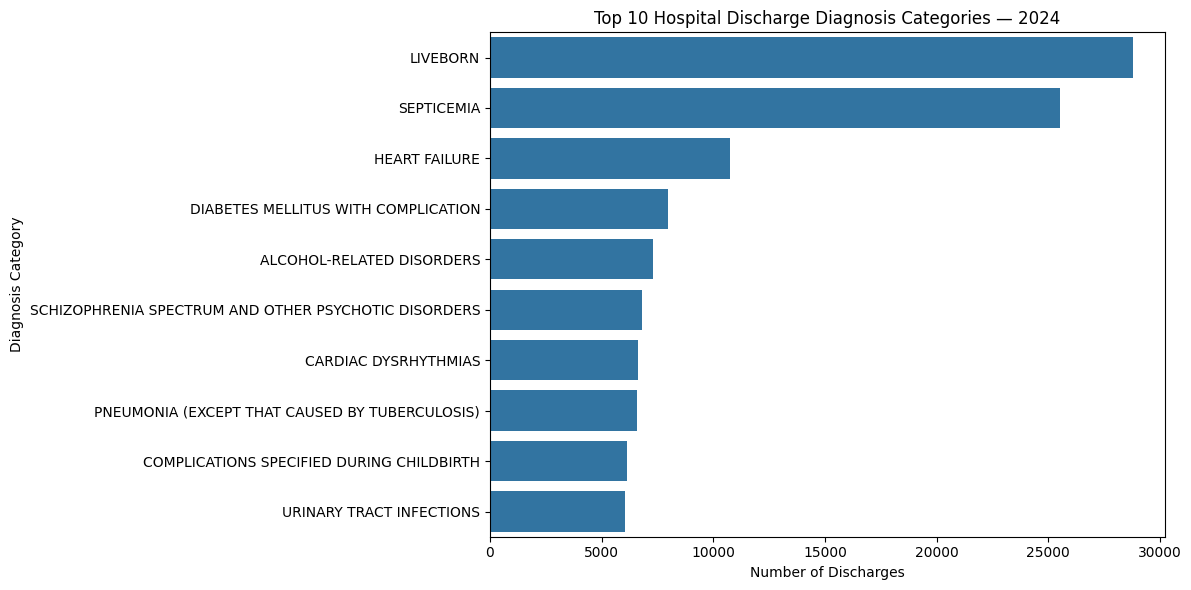

In [21]:
# Count the 10 most frequent categories and plot their discharge volumes.
top_diagnoses = hospital_df["Diagnosis"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_diagnoses.values, y=top_diagnoses.index)
plt.title("Top 10 Hospital Discharge Diagnosis Categories — 2024")
plt.xlabel("Number of Discharges")
plt.ylabel("Diagnosis Category")
plt.tight_layout()
plt.show()


### What I found

**Newborn birth hospitalizations** were the most common category in the 400,000-record sample, with **28,773 discharges (7.19%)**. **Septicemia** came next at **25,540 (6.39%)**, followed by **heart failure** at **10,730 (2.68%)**.

Septicemia stood out to me because it was one of the most frequently recorded diagnoses. These counts tell me how often categories appear **in this sample**; they aren't statewide disease rates. And I wouldn't describe `LIVEBORN` as a disease.

## 7. Question 2 — Which hospitalizations have the highest average cost?

For this question, I used **diagnosis-related groups (DRGs)**, which classify hospitalizations by the type of care involved. A DRG might refer to a transplant, a procedure, or newborn care—not just an illness.

I used the **average cost per discharge** rather than total cost because I wanted to see which categories tend to be most expensive for an individual hospitalization.

In [22]:
# Familiarize ourselves with the 10 most common DRG categories.
hospital_df["DRG Description"].value_counts().head(10)


,count
DRG Description,
"NEONATE BIRTH WEIGHT > 2499 GRAMS, NORMAL NEWBORN OR NEONATE WITH OTHER PROBLEM",22922
SEPTICEMIA AND DISSEMINATED INFECTIONS,21633
VAGINAL DELIVERY,20934
HEART FAILURE,10344
CESAREAN SECTION WITHOUT STERILIZATION,10269
KIDNEY AND URINARY TRACT INFECTIONS,5792
OTHER PNEUMONIA,5742
SCHIZOPHRENIA,5565
MAJOR RESPIRATORY INFECTIONS AND INFLAMMATIONS,5436


### Making the DRG names easier to read

Some original DRG descriptions are very long and technical. For the charts, I replaced a few of them with shorter labels in `hospital_readable_df`. I kept `hospital_df` as the unchanged reference, so I could still check the original wording when needed.

In [23]:
hospital_df['DRG Description'].nunique()

336

In [24]:
# Shorten a few DRG descriptions for clearer tables and charts.

hospital_readable_df = hospital_df.copy()

hospital_readable_df['DRG Description'] = hospital_readable_df['DRG Description'].replace({
    "NEONATE BIRTH WEIGHT 500-749 GRAMS WITHOUT MAJOR PROCEDURE":
        "Newborn 1.1–1.7 lb",

    "NEONATE BIRTH WEIGHT < 1500 GRAMS WITH MAJOR PROCEDURE":
        "Newborn under 3.3 lb + Surgery",

    "NEONATE BIRTH WEIGHT 750-999 GRAMS WITHOUT MAJOR PROCEDURE":
        "Newborn 1.7–2.2 lb",

    "NEONATE BIRTH WEIGHT 1500-2499 GRAMS WITH MAJOR PROCEDURE":
        "Newborn 3.3–5.5 lb + Surgery",

    "NEONATE BIRTH WEIGHT 1000-1249 GRAMS WITH RESPIRATORY DISTRESS SYNDROME OR OTHER MAJOR RESPIRATORY CONDITION OR MAJOR ANOMALY":
        "Newborn 2.2–2.8 lb + Serious Illness",

    "TRACHEOSTOMY WITH MV >96 HOURS WITH EXTENSIVE PROCEDURE":
        "Ventilator 4+ Days + Major Surgery",

    "HEART AND/OR LUNG TRANSPLANT":
        "Heart or Lung Transplant",

    "NEONATE WITH ECMO":
        "Newborn on Heart-Lung Support",

    "EXTENSIVE THIRD DEGREE BURNS WITH SKIN GRAFT":
        "Severe Burns + Skin Grafts",

    "TRACHEOSTOMY WITH MV >96 HOURS WITHOUT EXTENSIVE PROCEDURE":
        "Ventilator 4+ Days + Airway Surgery",

        "CHIMERIC ANTIGEN RECEPTOR (CAR) T-CELL AND OTHER IMMUNOTHERAPIES":	"Advanced Cancer Immune Treatments"

})






In [25]:
# Calculate and rank the 10 highest DRG average costs (not total costs).
top_costs = (
    hospital_readable_df.groupby("DRG Description")["Costs"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
top_costs


,Costs
DRG Description,
Heart or Lung Transplant,"709,029.98"
Newborn under 3.3 lb + Surgery,"592,886.31"
Advanced Cancer Immune Treatments,"460,492.55"
Newborn 1.1–1.7 lb,"452,378.65"
IMPLANTABLE HEART ASSIST SYSTEMS,"451,418.56"
Newborn on Heart-Lung Support,"444,845.78"
Ventilator 4+ Days + Major Surgery,"422,059.41"
Severe Burns + Skin Grafts,"372,162.68"
Newborn 3.3–5.5 lb + Surgery,"353,081.58"


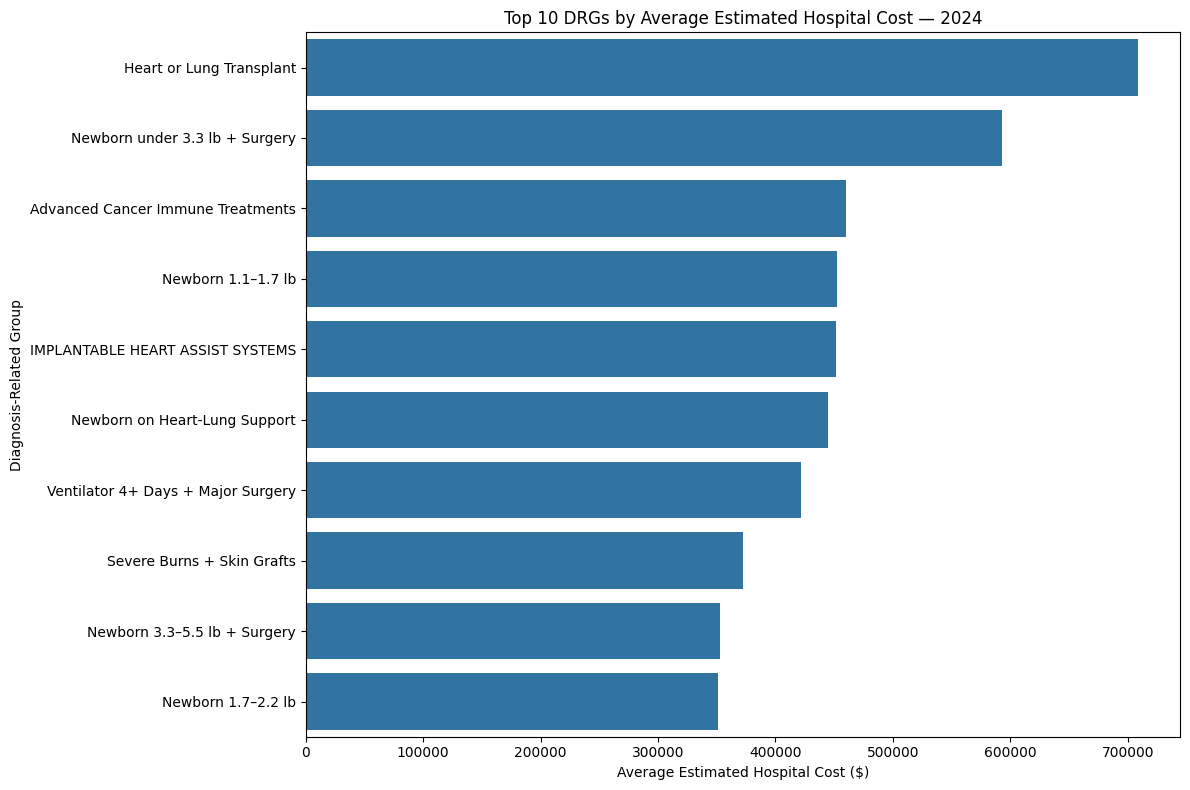

In [26]:
# Compare the top 10 average DRG costs using Seaborn.
plt.figure(figsize=(12, 8))
sns.barplot(x=top_costs.values, y=top_costs.index)
plt.title("Top 10 DRGs by Average Estimated Hospital Cost — 2024")
plt.xlabel("Average Estimated Hospital Cost ($)")
plt.ylabel("Diagnosis-Related Group")
plt.tight_layout()
plt.show()


### What I found

The **heart or lung transplant** DRG had the highest average estimated hospital cost in my sample: **$709,029.98 per discharge**. Several types of specialized newborn care and advanced cancer immune treatments also appeared near the top.

This was a good reminder that the average can be very high for a complex type of care, even when that kind of hospitalization isn't common. These are **estimated costs to the hospital**, not what a patient was billed.

### A quick check on those averages

I also wanted to know how many discharges were behind the numbers. Comparing the **count, mean, and median** helped me see whether a high average might be influenced by a smaller group of expensive hospitalizations.

In [27]:
# Count discharges and compare mean versus median costs for the top 10 DRGs.
hospital_readable_df.groupby("DRG Description")["Costs"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False).head(10)


,count,mean,median
DRG Description,,,
Heart or Lung Transplant,116,"709,029.98","519,633.23"
Newborn under 3.3 lb + Surgery,34,"592,886.31","388,761.45"
Advanced Cancer Immune Treatments,118,"460,492.55","412,447.54"
Newborn 1.1–1.7 lb,42,"452,378.65","382,370.97"
IMPLANTABLE HEART ASSIST SYSTEMS,43,"451,418.56","388,315.59"
Newborn on Heart-Lung Support,8,"444,845.78","353,097.60"
Ventilator 4+ Days + Major Surgery,500,"422,059.41","321,149.03"
Severe Burns + Skin Grafts,11,"372,162.68","320,701.66"
Newborn 3.3–5.5 lb + Surgery,26,"353,081.58","263,216.15"


For example, the heart or lung transplant DRG had **116 discharges**, an average estimated cost of **$709,029.98**, and a median of **$519,633.23**. Because the mean is noticeably higher than the median, some especially expensive cases are pulling the average upward. I kept the detailed breakdown below as a supporting check.

In [28]:
# Optional drill-down: describe costs for just the transplant DRG.
hospital_readable_df.loc[
    hospital_df["DRG Description"] == "HEART AND/OR LUNG TRANSPLANT",
    "Costs"
].describe()


,Costs
count,116.00
mean,"709,029.98"
std,"619,394.21"
min,"110,746.48"
25%,"309,087.98"
50%,"519,633.23"
75%,"957,179.63"
max,"4,147,357.14"


## 8. Question 3 — Which hospitalizations have the longest stays?

Next, I ranked DRGs by their **average length of stay** and graphed the top 10.

I kept the earlier `120+` limitation in mind here: stays longer than 120 days may be recorded as 120 in my working data, so some averages could be lower than the true values.

In [29]:
hospital_readable_df.groupby('DRG Description')['Length of Stay'].mean().sort_values(ascending=False).head(10)

,Length of Stay
DRG Description,
Newborn 1.1–1.7 lb,94.21
Newborn under 3.3 lb + Surgery,90.91
Newborn 1.7–2.2 lb,73.31
Newborn 3.3–5.5 lb + Surgery,59.12
Newborn 2.2–2.8 lb + Serious Illness,58.42
Ventilator 4+ Days + Major Surgery,56.10
Heart or Lung Transplant,50.75
Newborn on Heart-Lung Support,49.88
Severe Burns + Skin Grafts,49.73


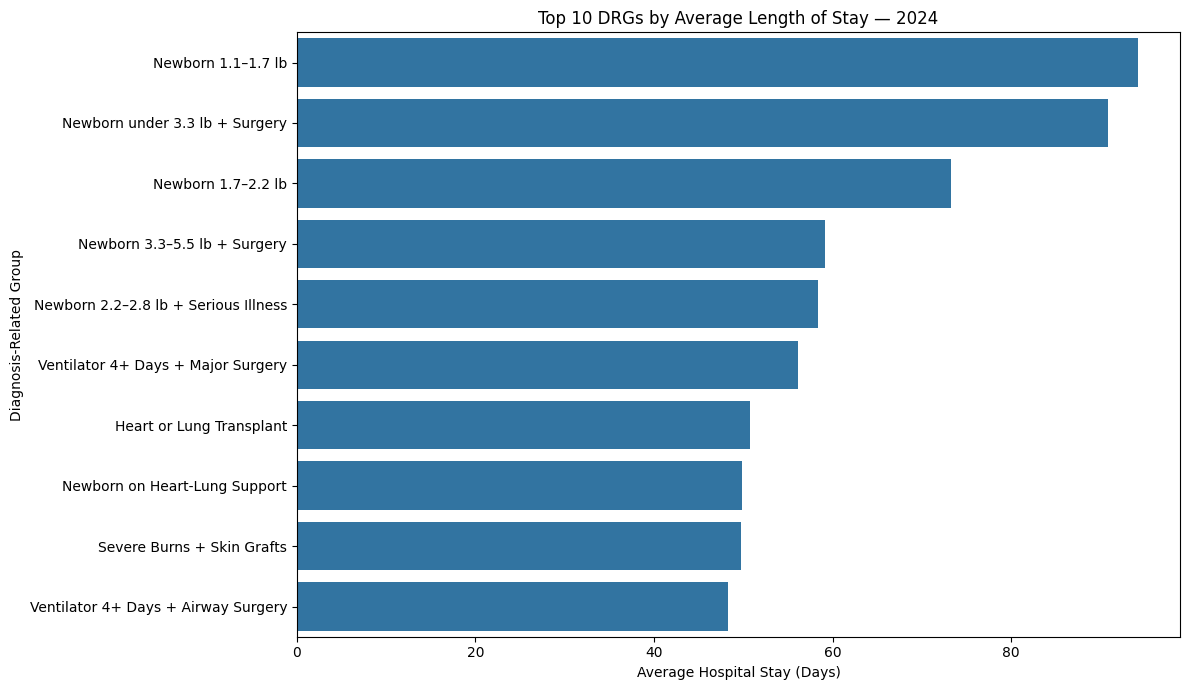

In [30]:
top_stays = ( hospital_readable_df.groupby('DRG Description')['Length of Stay'].mean(

).sort_values(ascending = False).head(10)
)
plt.figure(figsize=(12,7))

sns.barplot(

            x=top_stays.values,
            y=top_stays.index
)

plt.title('Top 10 DRGs by Average Length of Stay — 2024')
plt.xlabel("Average Hospital Stay (Days)")
plt.ylabel('Diagnosis-Related Group')
plt.tight_layout()
plt.show()


### What I found

The longest average stays were mostly linked to **very low birthweight newborns and other serious neonatal conditions**. The DRG labeled **“Newborn 1.1–1.7 lb”** had the highest average stay at **94.21 days**, followed by **“Newborn under 3.3 lb + Surgery”** at **90.91 days**. **Heart or lung transplant** was also in the top 10, with an average stay of **50.75 days**.

This helped me understand how different kinds of hospital care can require very different lengths of stay. These are averages, though—not how long every patient in those groups stayed.

## 9. Question 4 — How does illness severity relate to hospital costs?

I wanted to look at severity **within one DRG**, rather than comparing completely different types of hospitalizations. I chose **heart or lung transplant** and compared the average estimated costs for Moderate, Major, and Extreme severity.

I also checked the number of discharges in each group, because an average based on a handful of cases needs extra care when interpreting it.

In [31]:
# Compare average estimated costs by severity within the heart or lung transplant DRG.

hospital_readable_df[hospital_readable_df

  ['DRG Description'] == 'Heart or Lung Transplant'].groupby(

      'Severity')['Costs'].mean().round(2)







,Costs
Severity,
Extreme,"815,291.35"
Major,"509,593.10"
Moderate,"189,839.19"


In [32]:
# Check how many discharges are behind each severity average.

hospital_readable_df[hospital_readable_df['DRG Description']
                     == 'Heart or Lung Transplant'].groupby('Severity')['Costs'
                     ].agg(['count', 'mean']).round(2)





,count,mean
Severity,,
Extreme,83,"815,291.35"
Major,26,"509,593.10"
Moderate,7,"189,839.19"


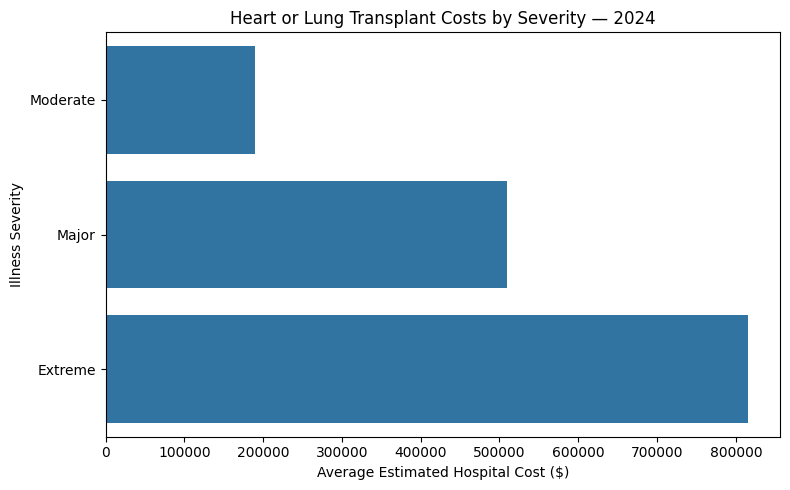

In [33]:
severity_costs = (
    hospital_readable_df
     [hospital_readable_df['DRG Description'] == 'Heart or Lung Transplant'

      ].groupby('Severity')['Costs'].mean().reindex([ 'Moderate','Major', 'Extreme'

      ])
)

plt.figure(figsize = (8,5))
sns.barplot(
    x=severity_costs.values,
    y= severity_costs.index
)
plt.title('Heart or Lung Transplant Costs by Severity — 2024')
plt.xlabel('Average Estimated Hospital Cost ($)')
plt.ylabel('Illness Severity')
plt.tight_layout()
plt.show()







### What I found

Within the heart or lung transplant DRG, average estimated costs increased across the recorded severity levels:

| Recorded severity | Discharges | Average estimated hospital cost |
|---|---:|---:|
| Moderate | 7 | $189,839.19 |
| Major | 26 | $509,593.10 |
| Extreme | 83 | $815,291.35 |

**Extreme** cases had the highest average cost. It makes sense to investigate how severity and resource use relate, but this table by itself doesn't establish what caused the higher costs. I also kept the discharge counts visible because the Moderate group only has **7 cases**.

## 10. Question 5 — How do diagnoses, costs, and stays differ by demographics?

Here I compared the most common recorded diagnosis for each **age group, gender, and race category**, along with its discharge count, average estimated cost, and average stay.

I looked at the size of each demographic category first, then worked on finding **one leading diagnosis per group** rather than trying to read thousands of different combinations at once.

In [34]:
hospital_readable_df['Age Group'].value_counts()



,count
Age Group,
70 or Older,125449
50-69,109727
30-49,80336
0-17,49191
18-29,35297


In [35]:
hospital_readable_df['Gender'].value_counts()

,count
Gender,
F,216265
M,183634
U,101


In [36]:
hospital_readable_df['Race'].value_counts()

,count
Race,
White,206996
Other Race,114531
Black/African American,71660
Multi-racial,6813


### How I narrowed the demographic analysis

My first approach grouped age, gender, race, **and** diagnosis together. It worked as a calculation, but the result had too many combinations to make a clear comparison. I left that earlier attempt commented out below for reference and used a simpler approach: find the **most common diagnosis within each demographic group**, then compare the counts, costs, and stays.

In [37]:
# My earlier demographic summary approach (saved for reference):
# Age group, gender, race — who the hospitalization involved
# Diagnosis — the recorded condition
# Diagnosis count — how many discharges matched the combination
# Average estimated hospital cost
# Average hospital stay (days)
# This approach combined too many categories to be easy to interpret.


#demographic_summary = (
#    hospital_readable_df.groupby( ['Age Group', 'Gender', 'Race', 'Diagnosis']
 #  ).agg(Diagnosis_count = ('Diagnosis', 'size'),
  #     Average_cost = ('Costs', 'mean'),
  #    Average_stay = ('Length of Stay', 'mean')
  # ).round(2).reset_index()
#                       )
#display(demographic_summary)


In [38]:

for demographic in ['Age Group', 'Gender', 'Race']:

    summary = (
        hospital_readable_df.groupby([demographic, 'Diagnosis'])
        .agg(
            Diagnosis_count=('Diagnosis', 'size'),
            Average_cost=('Costs', 'mean'),
            Average_stay=('Length of Stay', 'mean')
        )
        .round(2)
        .reset_index()
    )

    top_diagnoses = (
        summary.sort_values('Diagnosis_count', ascending=False)
        .drop_duplicates(subset=demographic)
    )

    print(demographic)
    display(top_diagnoses)






Age Group


,Age Group,Diagnosis,Diagnosis_count,Average_cost,Average_stay
171,0-17,LIVEBORN,28773,"13,547.11",4.01
1893,70 or Older,SEPTICEMIA,12340,"40,631.99",9.30
1503,50-69,SEPTICEMIA,8355,"48,642.86",10.12
1090,30-49,SEPTICEMIA,3487,"42,656.05",8.55
419,18-29,COMPLICATIONS SPECIFIED DURING CHILDBIRTH,2670,"12,145.71",2.51


Gender


,Gender,Diagnosis,Diagnosis_count,Average_cost,Average_stay
656,M,LIVEBORN,14647,"14,389.34",4.15
226,F,LIVEBORN,14089,"12,680.76",3.87
897,U,LIVEBORN,37,"10,027.34",4.11


Race


,Race,Diagnosis,Diagnosis_count,Average_cost,Average_stay
1622,White,SEPTICEMIA,14459,"36,784.91",8.64
1002,Other Race,LIVEBORN,11996,"13,947.94",4.11
384,Black/African American,SEPTICEMIA,4216,"56,479.01",11.49
597,Multi-racial,LIVEBORN,737,"16,866.00",4.67


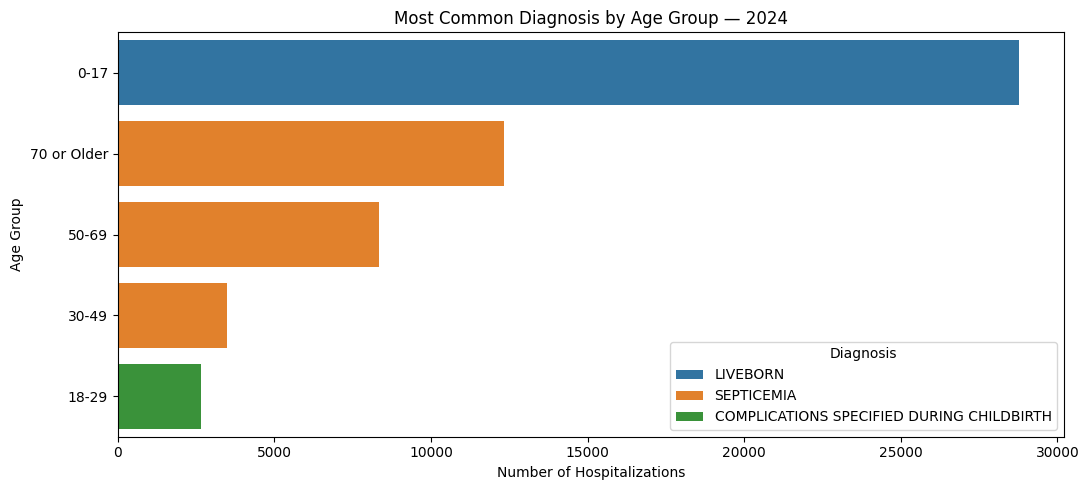

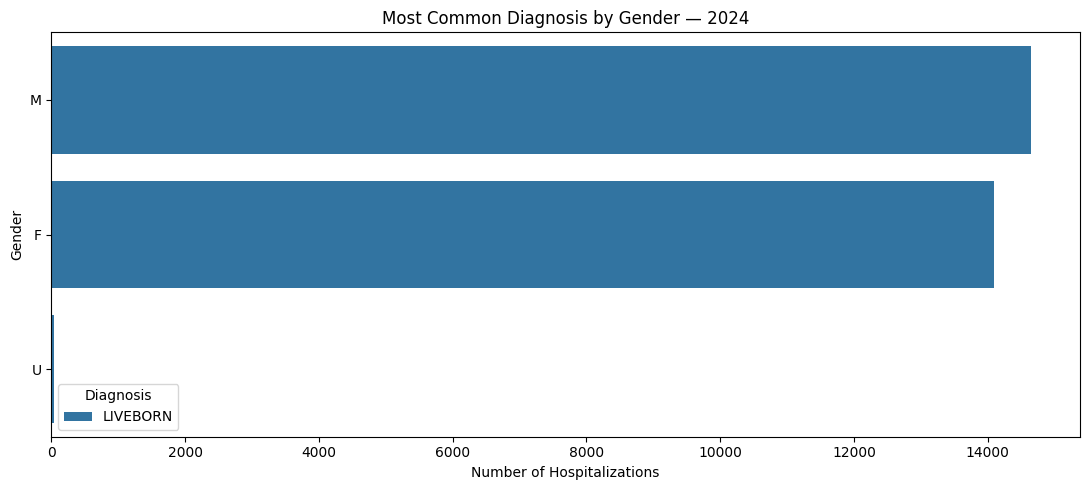

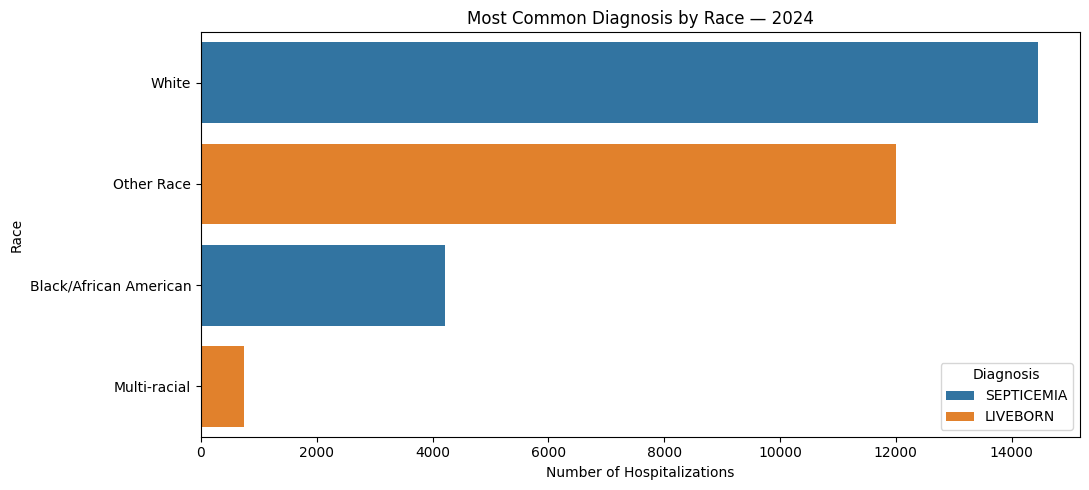

In [39]:

for demographic in ['Age Group', 'Gender', 'Race']:

    summary = (
        hospital_readable_df.groupby([demographic, 'Diagnosis'])
        .agg(
            Diagnosis_count=('Diagnosis', 'size'),
            Average_cost=('Costs', 'mean'),
            Average_stay=('Length of Stay', 'mean')
        )
        .round(2)
        .reset_index()
    )

    top_diagnoses = (
        summary.sort_values('Diagnosis_count', ascending=False)
        .drop_duplicates(subset=demographic) )

    plt.figure(figsize=(11,5))
    sns.barplot(
        data =top_diagnoses,
        x='Diagnosis_count',
        y=demographic,
        hue='Diagnosis')


    plt.title(f'Most Common Diagnosis by {demographic} — 2024')
    plt.xlabel('Number of Hospitalizations')
    plt.ylabel(demographic)
    plt.tight_layout()
    plt.show()





### What stood out in the demographic comparison

**By age:** Newborn birth hospitalizations led for ages **0–17** (**28,773 discharges**). For ages **18–29**, the most common diagnosis category was **complications specified during childbirth** (**2,670 discharges**). For every age group **30 and older**, septicemia came out on top. Among those older groups, ages **50–69** had the longest average stay for septicemia at **10.12 days**.

**By gender:** Newborn birth hospitalizations were the leading category for both male (**14,647**) and female (**14,089**) records. Their average stays were **4.15** and **3.87 days**, respectively.

**By race:** Septicemia was the most common recorded diagnosis among both White and Black/African American patients in this sample. This is where I noticed a difference worth exploring:

| Septicemia discharge measure | Black/African American | White |
|---|---:|---:|
| Hospitalizations | 4,216 | 14,459 |
| Average estimated cost | $56,479.01 | $36,784.91 |
| Average hospital stay | 11.49 days | 8.64 days |

What caught my attention was that **the Black/African American group had fewer septicemia discharges in this sample, but a higher average estimated cost and a longer average stay per discharge**. The difference was about **$19,694** and **2.85 days** per hospitalization.

That doesn't tell me *why* the difference exists, so I kept investigating instead of jumping to a conclusion.

## 11. Additional investigation — Septicemia, race, and illness severity

The septicemia comparison raised a question for me: **Could differences in recorded illness severity help explain the higher average cost and longer stays?**

I filtered the dataset to septicemia discharges classified as **White** or **Black/African American**, then compared discharge counts, mean estimated costs, and mean stays **within each severity level**. That way I wasn't comparing all severity levels together.

In [40]:
# Compare septicemia discharge counts, average costs, and stays by race and severity.

septicemia = hospital_readable_df[
(hospital_readable_df['Diagnosis'] == 'SEPTICEMIA') & (hospital_readable_df['Race'].isin(['White', 'Black/African American']))
]
severity_comparison = (
    septicemia.groupby(['Race', 'Severity']).agg(

            Cases = ('Diagnosis', 'size'),
            Average_cost = ('Costs', 'mean'),
            Average_stay = ('Length of Stay', 'mean')

    ).round(2)

)
display( severity_comparison)






Cases  Average_cost  Average_stay
Race                   Severity                                   
Black/African American Extreme    1851     92,202.60         17.13
                       Major      1601     33,350.75          8.14
                       Minor       100     11,708.02          3.25
                       Moderate    664     19,402.29          5.07
White                  Extreme    5678     62,404.40         12.92
                       Major      5785     23,827.14          6.72
                       Minor       433      9,392.01          2.99
                       Moderate   2563     13,903.24          4.44

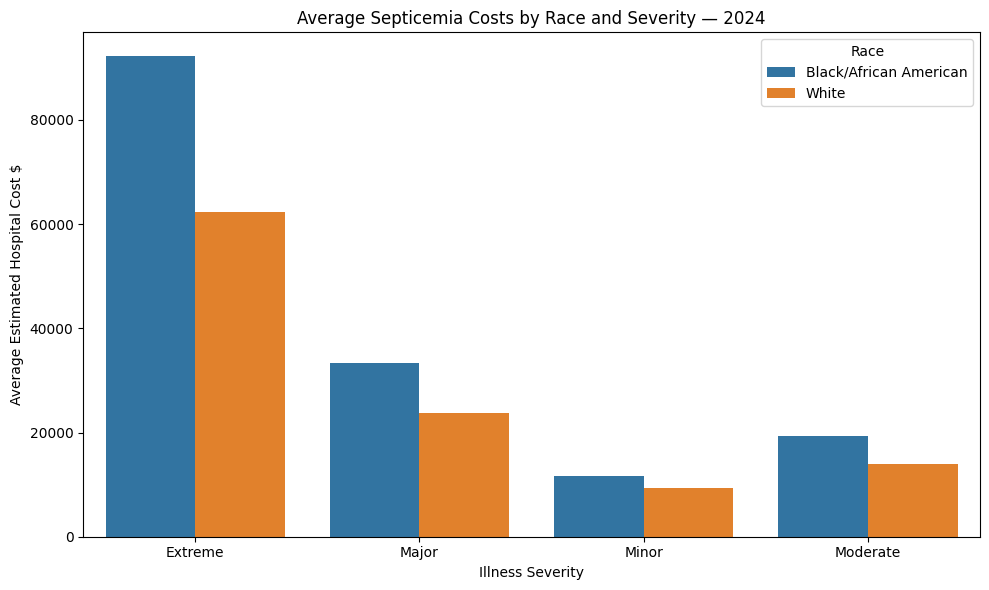

In [41]:
# Plot average septicemia costs by race and recorded severity.

plt.figure(figsize=(10,6))

sns.barplot(
    data = severity_comparison.reset_index(),
    x='Severity',
    y= 'Average_cost',
    hue='Race'
)

plt.title("Average Septicemia Costs by Race and Severity — 2024")
plt.xlabel("Illness Severity")
plt.ylabel("Average Estimated Hospital Cost $")

plt.tight_layout()
plt.show()




### What I found when I controlled for recorded severity

Even after separating septicemia discharges by severity, **Black/African American patients had higher average estimated costs and longer average stays than White patients in all four recorded severity categories** in this sample.

For **Extreme** severity, for example, average estimated costs were **$92,202.60** versus **$62,404.40**, and average stays were **17.13** versus **12.92 days**. There were **1,851 Black/African American** and **5,678 White** discharges in that category.

This was an important finding, but severity is still a broad classification. People in the same category may have different complications, treatment needs, medical histories, or hospitals. The difference is real **in my sample**; the cause isn't established here.

## 12. Looking closer — Septicemia by age, race, and severity

I didn't want to stop at severity alone. Age could also affect costs and length of stay, so I made one more comparison: **age group + race + severity** for septicemia.

This creates a detailed 40-row table, but the final `catplot()` turns it into **one figure with four panels**—one for each severity level. That makes the average cost differences easier to see across all five age groups without losing any severity categories.

In [42]:
age_race_severity =(
    septicemia.groupby(['Age Group', 'Race', 'Severity']).agg(
        Cases = ('Diagnosis', 'size'),
        Average_cost = ('Costs', 'mean'),
        Average_stay =('Length of Stay', 'mean')

    ).round(2).reset_index()

)
display(age_race_severity)

,Age Group,Race,Severity,Cases,Average_cost,Average_stay
0,0-17,Black/African American,Extreme,14,"81,945.76",15.71
1,0-17,Black/African American,Major,18,"23,095.48",5.00
2,0-17,Black/African American,Minor,5,"11,935.77",3.00
3,0-17,Black/African American,Moderate,25,"11,443.82",2.84
4,0-17,White,Extreme,20,"66,515.76",11.20
5,0-17,White,Major,55,"28,859.02",5.93
6,0-17,White,Minor,20,"9,786.79",2.85
7,0-17,White,Moderate,43,"20,767.77",4.07
8,18-29,Black/African American,Extreme,36,"69,933.73",16.25
9,18-29,Black/African American,Major,71,"33,842.51",7.04


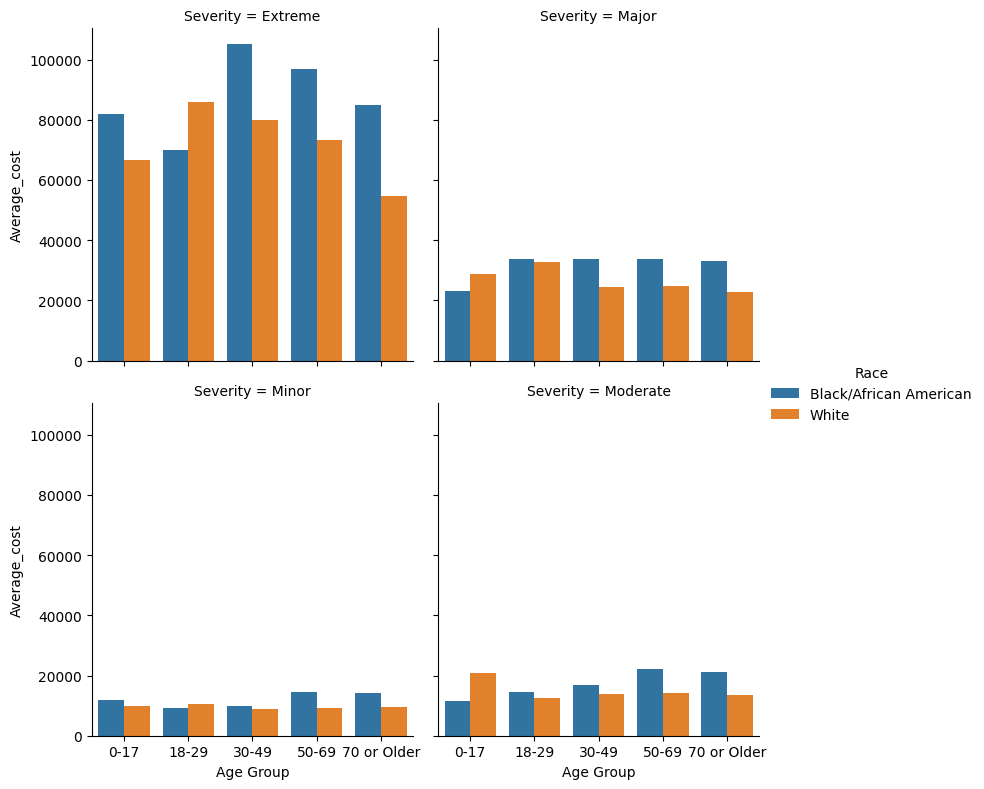

In [43]:


sns.catplot(
    data=age_race_severity,
    x="Age Group",
    y="Average_cost",
    hue="Race",
    col="Severity",
    kind="bar",
    col_wrap=2,
    height=4,
    errorbar=None
)

plt.show()


### What the age-and-severity comparison showed

Looking at age and severity together made the pattern clearer, but also more nuanced. Among patients ages **50–69** and **70 or older**, Black/African American septicemia discharges had **higher average estimated costs and longer average stays at every recorded severity level**. The younger groups were more mixed, especially when there were very few cases.

One detail really stood out to me: among patients **ages 30–49** with **Minor** severity, the Black/African American group had **35 discharges**, an average stay of **2.51 days**, and an average estimated cost of **$9,916.09**. The White group had **128 discharges**, an average stay of **2.77 days**, and an average cost of **$8,804.93**.

So in that specific comparison, the Black/African American group actually had a **shorter average stay, but a higher average cost**. That showed me why it's important not to assume costs come down to just the number of cases or days in the hospital. Hospital costs can also reflect the care delivered and where that care takes place.

Across the **20 age-by-severity comparisons**, the Black/African American group had a higher mean estimated cost in **16** and a longer mean stay in **15**. Some groups were small, so I wouldn't treat every difference as equally reliable. Still, the overall pattern is worth looking into further.

## Tableau handoff — Save the cleaned analysis dataset

The charts and findings above finish my Python analysis. The optional cell below saves the **15-column working dataset with shorter, readable DRG labels** as a CSV in Google Drive. I can use that file as my data source when I build the Tableau dashboard.

Run it once in Colab after the earlier cells have run. It won't change the original `Hospital_2024_400K.csv`.

In [45]:
# Export the cleaned working data for my Tableau dashboard.
hospital_readable_df.to_csv(
    "/content/drive/MyDrive/Hospital_2024_Tableau.csv",
    index=False
)

## Final thoughts — What this project taught me

This project started with a simple question about what shows up most often in hospital discharge records. By the end, I had explored **diagnoses, treatment costs, hospital stays, severity, and demographic differences** using Python. I also got much more comfortable with cleaning data, `groupby()`, averages, sorting, and creating charts that actually help tell the story.

The finding that stayed with me most was the septicemia comparison. **Black/African American patients generally had higher average estimated hospital costs and longer stays than White patients in this sample, and many of those differences remained when I compared age and recorded severity.** I think that's worth paying attention to, especially given how important equitable healthcare is. But I also know these numbers don't prove that anyone received worse care or tell us exactly what caused the differences.

**What the data can and can't tell me:**

- This is a **400,000-discharge working subset**, not a confirmed representative statewide sample. The comparisons are descriptive, not statewide rates.
- A discharge is a **hospitalization**, not necessarily a unique patient. A higher case count doesn't automatically mean a higher *average* cost.
- `Costs` means **estimated hospital costs**, not patient charges. Costs depend on more than length of stay.
- The recorded severity groups and age ranges are broad. I didn't control for the hospital, specific treatments, complications, or full medical history.
- Stays recorded as `120+` were represented as `120` days, which may slightly understate some averages. Small subgroups also need careful interpretation.

**My takeaway:** I finished the analysis I set out to do, learned a lot from the questions that came up along the way, and now have a solid set of findings to bring into **Tableau**. The Python phase of this project is complete.